In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import requests
from io import StringIO
import os
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r'nifty100_adjusted_close.csv')
df

,Date,ABB.NS,ADANIENSOL.NS,ADANIENT.NS,ADANIGREEN.NS,ADANIPORTS.NS,ADANIPOWER.NS,AMBUJACEM.NS,APOLLOHOSP.NS,ASIANPAINT.NS,...,TORNTPHARM.NS,TRENT.NS,TVSMOTOR.NS,ULTRACEMCO.NS,UNIONBANK.NS,VAML.NS,VBL.NS,VEDL.NS,WIPRO.NS,ZYDUSLIFE.NS
0,2023-11-20,4223.990723,727.500000,2146.985107,926.200012,792.950928,77.989998,416.636353,5432.395508,3038.151611,...,2050.614258,2616.172363,1699.467285,8385.050781,99.127350,NaN,415.170624,191.067993,185.061157,626.669373
1,2023-11-21,4222.338379,731.799988,2193.722656,926.599976,790.730713,78.500000,415.301941,5425.299316,3031.282227,...,2059.260742,2607.194824,1704.805176,8430.404297,100.225708,NaN,411.384979,191.666199,185.269241,629.674622
2,2023-11-22,4114.577637,726.950012,2169.754639,914.450012,781.406006,77.440002,409.470032,5490.004883,3031.040771,...,2051.391846,2620.561279,1719.286621,8480.309570,97.617104,NaN,408.828217,188.515625,185.084274,632.630554
3,2023-11-23,4139.987305,723.049988,2172.351074,930.700012,782.590088,76.339996,410.804413,5452.244141,3021.317627,...,2046.534058,2648.391602,1755.613892,8330.595703,97.113678,NaN,418.044556,186.760864,186.124725,622.333862
4,2023-11-24,4141.735840,729.099976,2222.484131,937.900024,785.007568,79.440002,409.519440,5360.296875,3034.087646,...,2031.232910,2643.054932,1779.238770,8283.111328,97.891678,NaN,423.415771,185.205551,183.118973,630.512207
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
737,2026-11-16,6895.000000,1452.599976,2659.000000,1406.599976,1893.000000,205.289993,382.000000,8771.000000,2572.899902,...,4691.200195,3203.699951,4453.000000,12270.000000,205.600006,385.250000,437.000000,253.000000,193.539993,1192.000000
738,2026-11-17,6923.000000,1493.699951,2745.100098,1429.900024,1917.000000,208.070007,390.200012,8712.500000,2625.000000,...,4668.799805,3176.300049,4466.200195,12290.000000,207.899994,397.000000,430.000000,255.029999,189.889999,1204.199951
739,2026-11-18,6851.000000,1490.000000,2684.199951,1404.099976,1902.599976,205.300003,384.799988,8821.000000,2580.300049,...,4610.700195,3190.000000,4369.000000,12428.000000,207.880005,374.500000,424.549988,245.399994,185.139999,1202.000000
740,2026-11-19,6951.000000,1473.400024,NaN,1425.000000,1917.099976,210.500000,396.799988,8738.000000,NaN,...,NaN,NaN,4601.399902,12560.000000,210.000000,371.000000,420.500000,243.699997,183.929993,1202.900024


## Cleaning the data frame and calculating the log returns.

In [3]:
df.columns

Index(['Date', 'ABB.NS', 'ADANIENSOL.NS', 'ADANIENT.NS', 'ADANIGREEN.NS',
       'ADANIPORTS.NS', 'ADANIPOWER.NS', 'AMBUJACEM.NS', 'APOLLOHOSP.NS',
       'ASIANPAINT.NS',
       ...
       'TORNTPHARM.NS', 'TRENT.NS', 'TVSMOTOR.NS', 'ULTRACEMCO.NS',
       'UNIONBANK.NS', 'VAML.NS', 'VBL.NS', 'VEDL.NS', 'WIPRO.NS',
       'ZYDUSLIFE.NS'],
      dtype='str', length=101)

In [4]:
# Count missing values in each column
print(df.isna().sum())

# Count non-finite values in numeric columns
print(np.isfinite(df.select_dtypes(include=np.number)).sum())

Date               0
ABB.NS             0
ADANIENSOL.NS      0
ADANIENT.NS        1
ADANIGREEN.NS      0
                ... 
VAML.NS          632
VBL.NS             0
VEDL.NS            0
WIPRO.NS           0
ZYDUSLIFE.NS       0
Length: 101, dtype: int64
ABB.NS           742
ADANIENSOL.NS    742
ADANIENT.NS      741
ADANIGREEN.NS    742
ADANIPORTS.NS    742
                ... 
VAML.NS          110
VBL.NS           742
VEDL.NS          742
WIPRO.NS         742
ZYDUSLIFE.NS     742
Length: 100, dtype: int64


In [5]:
prices = df.drop(columns=['Date']).copy()
print("Percentage of missing values in each column:")
missing_pct = prices.isna().mean() * 100

missing_summary = missing_pct.sort_values(ascending=False)

print(missing_summary.head(20))
# Remove stocks with more than 20% missing prices
prices = prices.loc[:, missing_pct <= 20]
# calc log returns on the remaining prices.
log_returns = np.log(prices / prices.shift(1))

Percentage of missing values in each column:
VAML.NS          85.175202
TMCV.NS          65.768194
TATACAP.NS       63.207547
ENRIN.NS         52.425876
HYUNDAI.NS       30.458221
SOLARINDS.NS      0.269542
SIEMENS.NS        0.269542
GRASIM.NS         0.134771
HDFCLIFE.NS       0.134771
SBILIFE.NS        0.134771
NESTLEIND.NS      0.134771
MAXHEALTH.NS      0.134771
HINDUNILVR.NS     0.134771
DMART.NS          0.134771
DRREDDY.NS        0.134771
BAJAJHLDNG.NS     0.134771
TORNTPHARM.NS     0.134771
TRENT.NS          0.134771
TATACONSUM.NS     0.134771
PIDILITIND.NS     0.134771
dtype: float64


In [6]:
# Check missing returns
missing_returns = log_returns.isna().sum().sort_values(ascending=False)

print(missing_returns.head(20))

SOLARINDS.NS     5
SIEMENS.NS       5
ADANIENT.NS      3
BANKBARODA.NS    3
DRREDDY.NS       3
BAJAJHLDNG.NS    3
ASIANPAINT.NS    3
MAXHEALTH.NS     3
HINDUNILVR.NS    3
JSWSTEEL.NS      3
KOTAKBANK.NS     3
HDFCLIFE.NS      3
GRASIM.NS        3
DMART.NS         3
BOSCHLTD.NS      3
POWERINDIA.NS    3
JINDALSTEL.NS    3
NESTLEIND.NS     3
PIDILITIND.NS    3
SBILIFE.NS       3
dtype: int64


In [7]:
# calculate the percentage of missing returns for each stock
missing_pct = (log_returns.isna().mean() * 100).sort_values(ascending=False)

print(missing_pct.head(20))

SOLARINDS.NS     0.673854
SIEMENS.NS       0.673854
ADANIENT.NS      0.404313
BANKBARODA.NS    0.404313
DRREDDY.NS       0.404313
BAJAJHLDNG.NS    0.404313
ASIANPAINT.NS    0.404313
MAXHEALTH.NS     0.404313
HINDUNILVR.NS    0.404313
JSWSTEEL.NS      0.404313
KOTAKBANK.NS     0.404313
HDFCLIFE.NS      0.404313
GRASIM.NS        0.404313
DMART.NS         0.404313
BOSCHLTD.NS      0.404313
POWERINDIA.NS    0.404313
JINDALSTEL.NS    0.404313
NESTLEIND.NS     0.404313
PIDILITIND.NS    0.404313
SBILIFE.NS       0.404313
dtype: float64


In [8]:
# keeping only those stocks with less than or equal to 20% missing returns
valid_stocks = missing_pct[missing_pct <= 20].index
log_returns_clean = log_returns[valid_stocks].copy()

In [9]:
# finding the correlation matrix to form the edges of the network graph
correlation_matrix = log_returns.corr(method='pearson', min_periods=60) #min_periods=60 ensures that we only consider pairs of stocks with at least 60 overlapping observations for correlation calculation.
correlation_matrix

,ABB.NS,ADANIENSOL.NS,ADANIENT.NS,ADANIGREEN.NS,ADANIPORTS.NS,ADANIPOWER.NS,AMBUJACEM.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AXISBANK.NS,...,TMPV.NS,TORNTPHARM.NS,TRENT.NS,TVSMOTOR.NS,ULTRACEMCO.NS,UNIONBANK.NS,VBL.NS,VEDL.NS,WIPRO.NS,ZYDUSLIFE.NS
ABB.NS,1.000000,0.338869,0.364475,0.315787,0.416009,0.286461,0.418073,0.208989,0.201429,0.292809,...,0.232283,0.182813,0.247839,0.270631,0.351773,0.398068,0.285367,0.181733,0.153504,0.280511
ADANIENSOL.NS,0.338869,1.000000,0.722000,0.807338,0.656641,0.666337,0.576775,0.083635,0.204169,0.276583,...,0.218957,0.140240,0.180004,0.270120,0.326672,0.373637,0.266607,0.217446,0.113678,0.228554
ADANIENT.NS,0.364475,0.722000,1.000000,0.737054,0.817021,0.673745,0.697240,0.184862,0.259867,0.353379,...,0.272470,0.169816,0.245772,0.322239,0.379909,0.436259,0.278224,0.199534,0.195212,0.287743
ADANIGREEN.NS,0.315787,0.807338,0.737054,1.000000,0.675785,0.684305,0.585559,0.103110,0.209966,0.288793,...,0.246269,0.179489,0.236242,0.272932,0.309421,0.388390,0.273112,0.182921,0.133350,0.256877
ADANIPORTS.NS,0.416009,0.656641,0.817021,0.675785,1.000000,0.593258,0.698951,0.206663,0.259138,0.370465,...,0.278005,0.182997,0.227514,0.331063,0.417189,0.473140,0.288844,0.195858,0.199116,0.304766
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UNIONBANK.NS,0.398068,0.373637,0.436259,0.388390,0.473140,0.374683,0.488745,0.162472,0.196161,0.404337,...,0.286795,0.123000,0.194765,0.303261,0.381737,1.000000,0.271254,0.196251,0.182460,0.243860
VBL.NS,0.285367,0.266607,0.278224,0.273112,0.288844,0.191089,0.315463,0.214788,0.218152,0.221162,...,0.154750,0.186158,0.225946,0.264844,0.326365,0.271254,1.000000,0.148772,0.127190,0.222737
VEDL.NS,0.181733,0.217446,0.199534,0.182921,0.195858,0.144536,0.267668,0.094230,0.100480,0.163950,...,0.174487,0.123156,0.148562,0.166881,0.201627,0.196251,0.148772,1.000000,0.120569,0.188652
WIPRO.NS,0.153504,0.113678,0.195212,0.133350,0.199116,0.088052,0.219290,0.188908,0.138366,0.162839,...,0.176335,0.119342,0.109876,0.184497,0.251787,0.182460,0.127190,0.120569,1.000000,0.166935


## Creating an adjacency matrix

In [10]:
# Create an unweighted adjacency matrix
threshold = 0.2

adjacency_matrix = (
    correlation_matrix.abs() >= threshold
).astype(int)

# Remove diagonal (self-connections) without modifying the original array
adjacency_matrix = adjacency_matrix * (
    1 - np.eye(len(adjacency_matrix), dtype=int)
)

print(adjacency_matrix.head())
print("Matrix shape:", adjacency_matrix.shape)
print("Number of connections:", adjacency_matrix.values.sum() // 2)

adjacency_matrix.to_csv("unweighted_adjacency_matrix_nifty100.csv")

               ABB.NS  ADANIENSOL.NS  ADANIENT.NS  ADANIGREEN.NS  \
ABB.NS              0              1            1              1   
ADANIENSOL.NS       1              0            1              1   
ADANIENT.NS         1              1            0              1   
ADANIGREEN.NS       1              1            1              0   
ADANIPORTS.NS       1              1            1              1   

               ADANIPORTS.NS  ADANIPOWER.NS  AMBUJACEM.NS  APOLLOHOSP.NS  \
ABB.NS                     1              1             1              1   
ADANIENSOL.NS              1              1             1              0   
ADANIENT.NS                1              1             1              0   
ADANIGREEN.NS              1              1             1              0   
ADANIPORTS.NS              0              1             1              1   

               ASIANPAINT.NS  AXISBANK.NS  ...  TMPV.NS  TORNTPHARM.NS  \
ABB.NS                     1            1  ...        1     

## using the library netwrokx now for further analysis

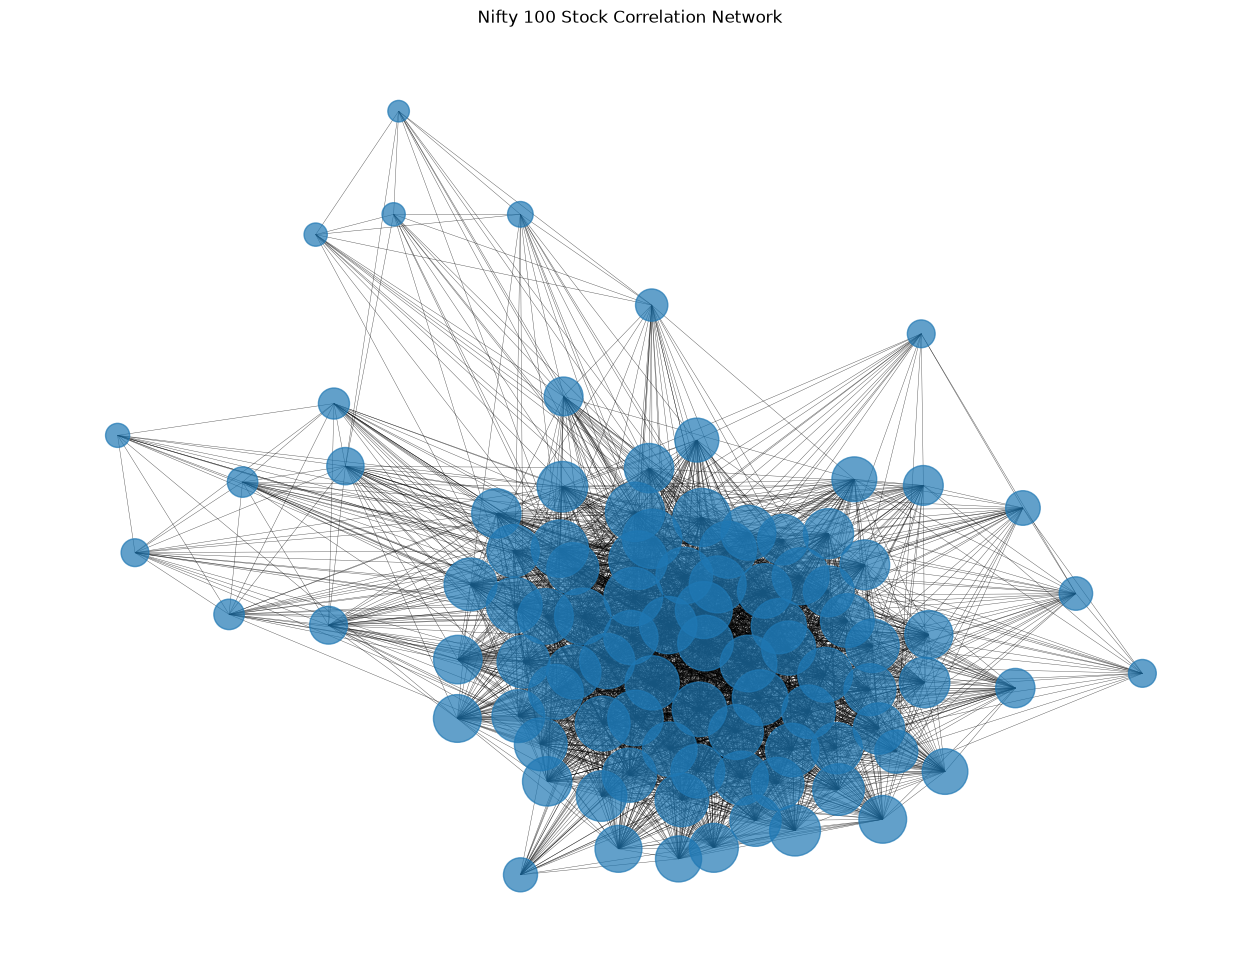

In [11]:
adjacency_matrix = pd.read_csv("unweighted_adjacency_matrix_nifty100.csv", index_col=0)
G = nx.from_pandas_adjacency(adjacency_matrix)
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42, k=0.3)

degrees = dict(G.degree())
node_sizes = [degrees[node] * 20 + 20 for node in G.nodes()]

nx.draw_networkx(
    G,
    pos,
    node_size=node_sizes,
    with_labels=False,
    width=0.3,
    alpha=0.7
)

plt.title("Nifty 100 Stock Correlation Network")
plt.axis("off")
plt.show()

## A. Degree Distribution Plot & Interpretation

In [12]:
# Calculate degree of every stock
degrees = dict(G.degree())

degree_values = list(degrees.values())

# Display degree statistics
degree_df = pd.DataFrame({
    'Stock': list(degrees.keys()),
    'Degree': degree_values
})

print(degree_df.sort_values(by='Degree', ascending=False).head(10))
print(degree_df['Degree'].describe())

            Stock  Degree
28         DLF.NS      90
58         M&M.NS      90
54    JSWSTEEL.NS      88
89  ULTRACEMCO.NS      88
56          LT.NS      86
11  BAJAJFINSV.NS      84
35      GRASIM.NS      84
38     HDFCAMC.NS      83
75  SHRIRAMFIN.NS      83
53      JIOFIN.NS      83
count    95.000000
mean     61.873684
std      21.567924
min      11.000000
25%      53.500000
50%      69.000000
75%      77.000000
max      90.000000
Name: Degree, dtype: float64


In [13]:
sns.set_theme(style="whitegrid", context="notebook")

degrees = dict(G.degree())

degree_df = pd.DataFrame({
    'Stock': list(degrees.keys()),
    'Degree': list(degrees.values())
})

print(degree_df.sort_values('Degree', ascending=False).head(10))

            Stock  Degree
28         DLF.NS      90
58         M&M.NS      90
54    JSWSTEEL.NS      88
89  ULTRACEMCO.NS      88
56          LT.NS      86
11  BAJAJFINSV.NS      84
35      GRASIM.NS      84
38     HDFCAMC.NS      83
75  SHRIRAMFIN.NS      83
53      JIOFIN.NS      83


In [14]:
# gives the 15 stocks with the highest degree in the network
degree_df.sort_values(
    by='Degree',
    ascending=False
).head(15)

,Stock,Degree
28,DLF.NS,90
58,M&M.NS,90
54,JSWSTEEL.NS,88
89,ULTRACEMCO.NS,88
56,LT.NS,86
11,BAJAJFINSV.NS,84
35,GRASIM.NS,84
38,HDFCAMC.NS,83
75,SHRIRAMFIN.NS,83
53,JIOFIN.NS,83


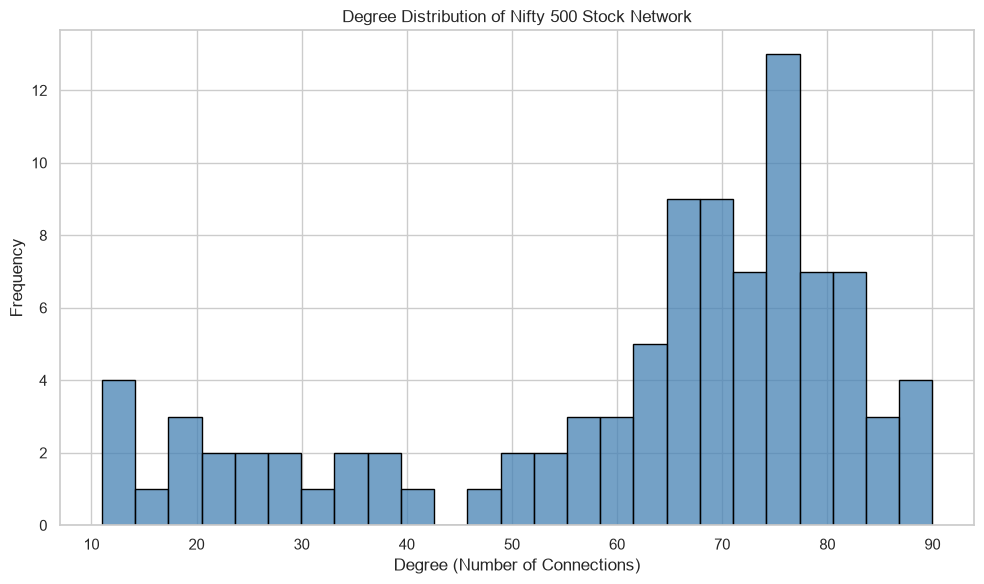

In [15]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=degree_df,
    x='Degree',
    bins=25,
    color='steelblue',
    edgecolor='black'
)

plt.title('Degree Distribution of Nifty 500 Stock Network')
plt.xlabel('Degree (Number of Connections)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

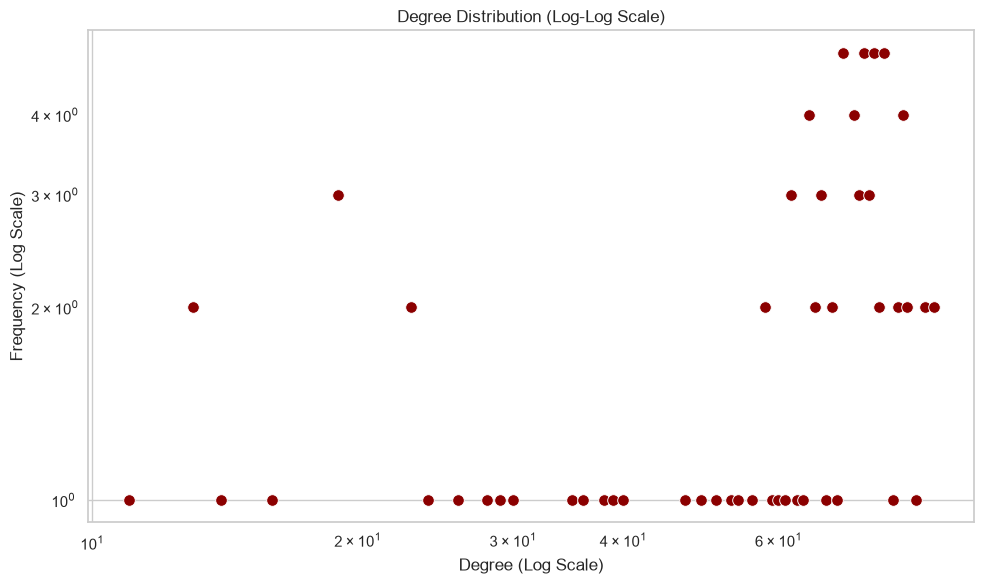

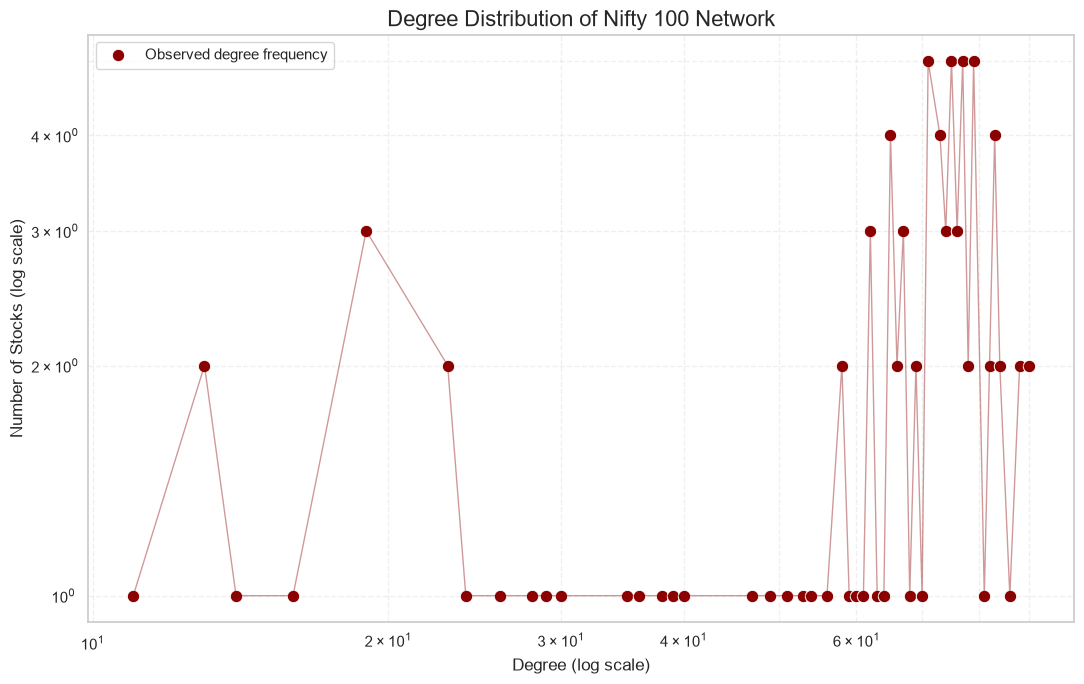

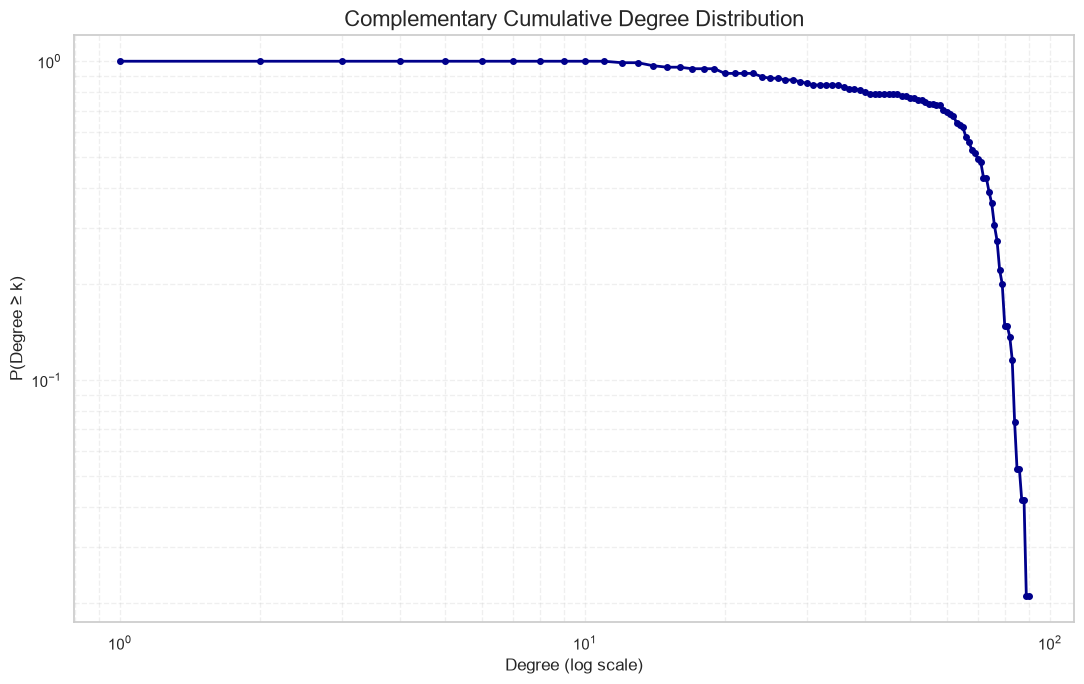

In [36]:
degree_counts = degree_df['Degree'].value_counts().sort_index()

# Remove degree zero and frequencies that cannot appear on a log scale
degree_counts = degree_counts[degree_counts.index > 0]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=degree_counts.index,
    y=degree_counts.values,
    color='darkred',
    s=70
)

plt.xscale('log')
plt.yscale('log')

plt.title('Degree Distribution (Log-Log Scale)')
plt.xlabel('Degree (Log Scale)')
plt.ylabel('Frequency (Log Scale)')

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 7))

sns.scatterplot(
    x=degree_counts.index,
    y=degree_counts.values,
    color='darkred',
    s=80,
    label='Observed degree frequency'
)

plt.plot(
    degree_counts.index,
    degree_counts.values,
    color='darkred',
    alpha=0.4,
    linewidth=1
)

plt.xscale('log')
plt.yscale('log')

plt.title('Degree Distribution of Nifty 100 Network',
          fontsize=16)

plt.xlabel('Degree (log scale)', fontsize=12)
plt.ylabel('Number of Stocks (log scale)', fontsize=12)

plt.grid(True, which='both', linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

degree_values = np.array(list(dict(G.degree()).values()))

degree_range = np.arange(1, degree_values.max() + 1)

ccdf = [
    np.mean(degree_values >= k)
    for k in degree_range
]

plt.figure(figsize=(11, 7))

plt.plot(
    degree_range,
    ccdf,
    marker='o',
    markersize=4,
    linewidth=2,
    color='darkblue'
)

plt.xscale('log')
plt.yscale('log')

plt.title('Complementary Cumulative Degree Distribution',
          fontsize=16)

plt.xlabel('Degree (log scale)', fontsize=12)
plt.ylabel('P(Degree ≥ k)', fontsize=12)

plt.grid(True, which='both', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

## B. Top-10 Centrality Leaderboard (The "Who's Who" of the Market)

In [17]:
# 1. Degree Centrality
degree_centrality = nx.degree_centrality(G)

# 2. Betweenness Centrality
betweenness_centrality = nx.betweenness_centrality(G)

# 3. Eigenvector Centrality
eigenvector_centrality = nx.eigenvector_centrality(
    G, max_iter=1000, tol=1e-06
)

In [18]:
# Create a centrality leaderboard
centrality_df = pd.DataFrame({
    'Stock': list(G.nodes()),
    'Degree Centrality': [degree_centrality[node] for node in G.nodes()],
    'Betweenness Centrality': [betweenness_centrality[node] for node in G.nodes()],
    'Eigenvector Centrality': [eigenvector_centrality[node] for node in G.nodes()]
})

print(centrality_df.head())

           Stock  Degree Centrality  Betweenness Centrality  \
0         ABB.NS           0.776596                0.002040   
1  ADANIENSOL.NS           0.712766                0.001046   
2    ADANIENT.NS           0.819149                0.003467   
3  ADANIGREEN.NS           0.776596                0.001994   
4  ADANIPORTS.NS           0.840426                0.003878   

   Eigenvector Centrality  
0                0.117305  
1                0.110004  
2                0.121821  
3                0.117417  
4                0.123986  


In [19]:
# Get the Top 10 stocks for each measure
# Top 10 by Degree Centrality
top_degree = centrality_df.sort_values(
    by='Degree Centrality', ascending=False
).head(10)

# Top 10 by Betweenness Centrality
top_betweenness = centrality_df.sort_values(
    by='Betweenness Centrality', ascending=False
).head(10)

# Top 10 by Eigenvector Centrality
top_eigenvector = centrality_df.sort_values(
    by='Eigenvector Centrality', ascending=False
).head(10)

print("TOP 10 - DEGREE CENTRALITY")
print(top_degree.to_string(index=False))

print("\nTOP 10 - BETWEENNESS CENTRALITY")
print(top_betweenness.to_string(index=False))

print("\nTOP 10 - EIGENVECTOR CENTRALITY")
print(top_eigenvector.to_string(index=False))

TOP 10 - DEGREE CENTRALITY
        Stock  Degree Centrality  Betweenness Centrality  Eigenvector Centrality
       DLF.NS           0.957447                0.017170                0.129505
       M&M.NS           0.957447                0.022703                0.127114
  JSWSTEEL.NS           0.936170                0.016596                0.127547
ULTRACEMCO.NS           0.936170                0.012913                0.128567
        LT.NS           0.914894                0.015120                0.126967
BAJAJFINSV.NS           0.893617                0.014892                0.123577
    GRASIM.NS           0.893617                0.009943                0.125539
   HDFCAMC.NS           0.882979                0.009589                0.125388
SHRIRAMFIN.NS           0.882979                0.006757                0.126291
    JIOFIN.NS           0.882979                0.008939                0.125512

TOP 10 - BETWEENNESS CENTRALITY
        Stock  Degree Centrality  Betweenness Cen

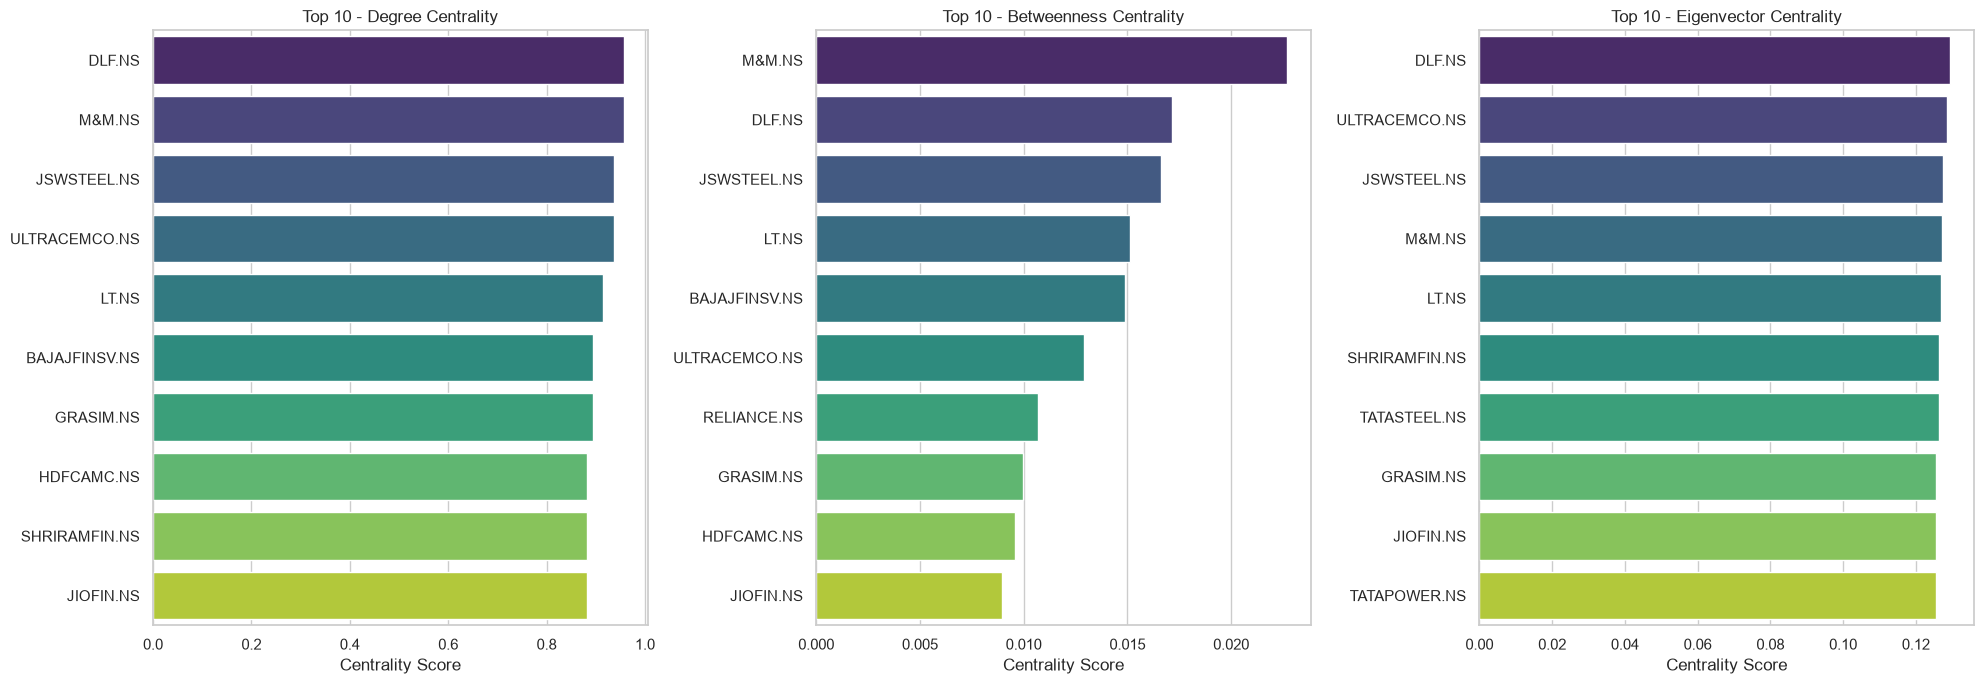

In [20]:
# Visualise the Top 10 leaderboard 
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

centralities = [
    (top_degree, 'Degree Centrality', 'Top 10 - Degree Centrality'),
    (top_betweenness, 'Betweenness Centrality', 'Top 10 - Betweenness Centrality'),
    (top_eigenvector, 'Eigenvector Centrality', 'Top 10 - Eigenvector Centrality')
]

for ax, (data, column, title) in zip(axes, centralities):
    sns.barplot(
        data=data,
        x=column,
        y='Stock',
        hue='Stock',
        palette='viridis',
        legend=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('Centrality Score')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

## C. Local Clustering Coefficient & Sector Homophily

In [21]:
# Average clustering coefficient of the entire network
avg_clustering = nx.average_clustering(G)

print("Average Clustering Coefficient:", avg_clustering)

Average Clustering Coefficient: 0.848569782568391


In [22]:
# Calculate individual stock clustering coefficients
clustering_coefficients = nx.clustering(G)

clustering_df = pd.DataFrame({
    'Stock': list(clustering_coefficients.keys()),
    'Clustering Coefficient': list(clustering_coefficients.values())
})

# Sort stocks by clustering coefficient
clustering_df = clustering_df.sort_values(
    by='Clustering Coefficient',
    ascending=False
)

print(clustering_df.head(15))

            Stock  Clustering Coefficient
92        VEDL.NS                1.000000
48  POWERINDIA.NS                0.997301
20         BSE.NS                0.964935
77   SOLARINDS.NS                0.962990
12  BAJAJHLDNG.NS                0.950680
49        IDEA.NS                0.944988
43    HINDZINC.NS                0.938632
66        ONGC.NS                0.936408
5   ADANIPOWER.NS                0.935516
85        TMPV.NS                0.933880
22     CGPOWER.NS                0.927404
32     ETERNAL.NS                0.924907
63  MUTHOOTFIN.NS                0.921635
61     MAZDOCK.NS                0.919946
1   ADANIENSOL.NS                0.914971


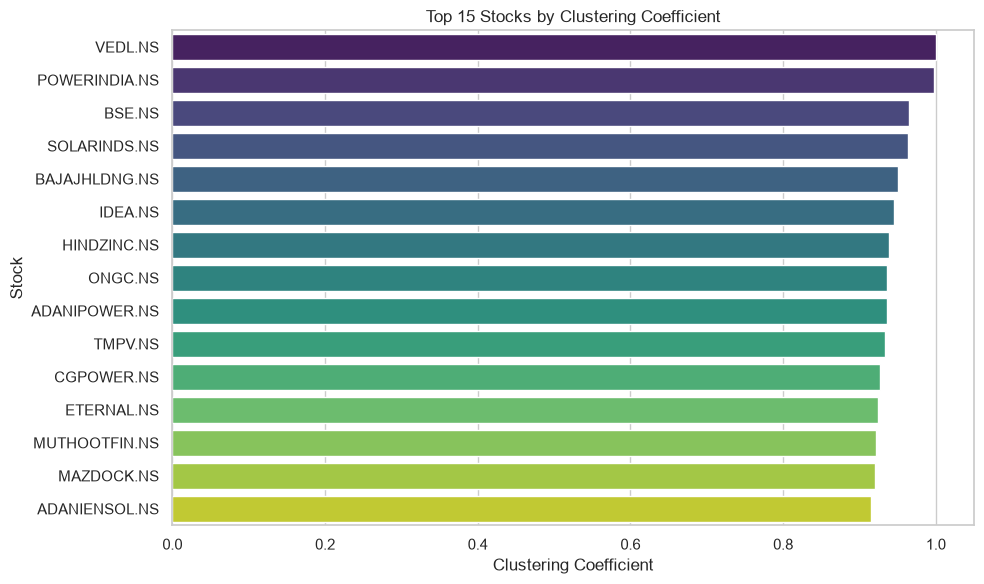

In [23]:
# Visualise the top 15 stocks
plt.figure(figsize=(10, 6))

sns.barplot(
    data=clustering_df.head(15),
    x='Clustering Coefficient',
    y='Stock',
    hue='Stock',
    palette='viridis',
    legend=False
)

plt.title('Top 15 Stocks by Clustering Coefficient')
plt.tight_layout()
plt.show()

### Sector homophily - Are stocks more likely to be connected to other stocks belonging to the same industry?

In [24]:
# Download and save adjusted close prices for a list of tickers for nifty500 stocks from Yahoo Finance
url = "https://nsearchives.nseindia.com/content/indices/ind_nifty100list.csv"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

nifty500 = pd.read_csv(StringIO(response.text))


In [25]:
print(nifty500.columns)

Index(['Company Name', 'Industry', 'Symbol', 'Series', 'ISIN Code'], dtype='str')


In [26]:
# Create ticker names matching your graph nodes
nifty500['Ticker'] = nifty500['Symbol'] + '.NS'

# Create sector mapping
sector_map = dict(zip(
    nifty500['Ticker'],
    nifty500['Industry']
))

In [27]:
# Assign sectors to your NetworkX graph
for stock in G.nodes():
    G.nodes[stock]['sector'] = sector_map.get(stock, 'Unknown')

In [28]:
print(pd.Series(
    nx.get_node_attributes(G, 'sector')
).value_counts())

Financial Services                22
Capital Goods                      9
Healthcare                         8
Automobile and Auto Components     8
Metals & Mining                    7
Fast Moving Consumer Goods         7
Power                              6
Oil Gas & Consumable Fuels         6
Information Technology             6
Construction Materials             3
Consumer Services                  3
Services                           2
Consumer Durables                  2
Telecommunication                  2
Chemicals                          2
Realty                             1
Construction                       1
Name: count, dtype: int64


In [29]:
sector_assortativity = nx.attribute_assortativity_coefficient(
    G, 'sector'
)

print("Sector Homophily:", sector_assortativity)

Sector Homophily: 0.020898898647508487


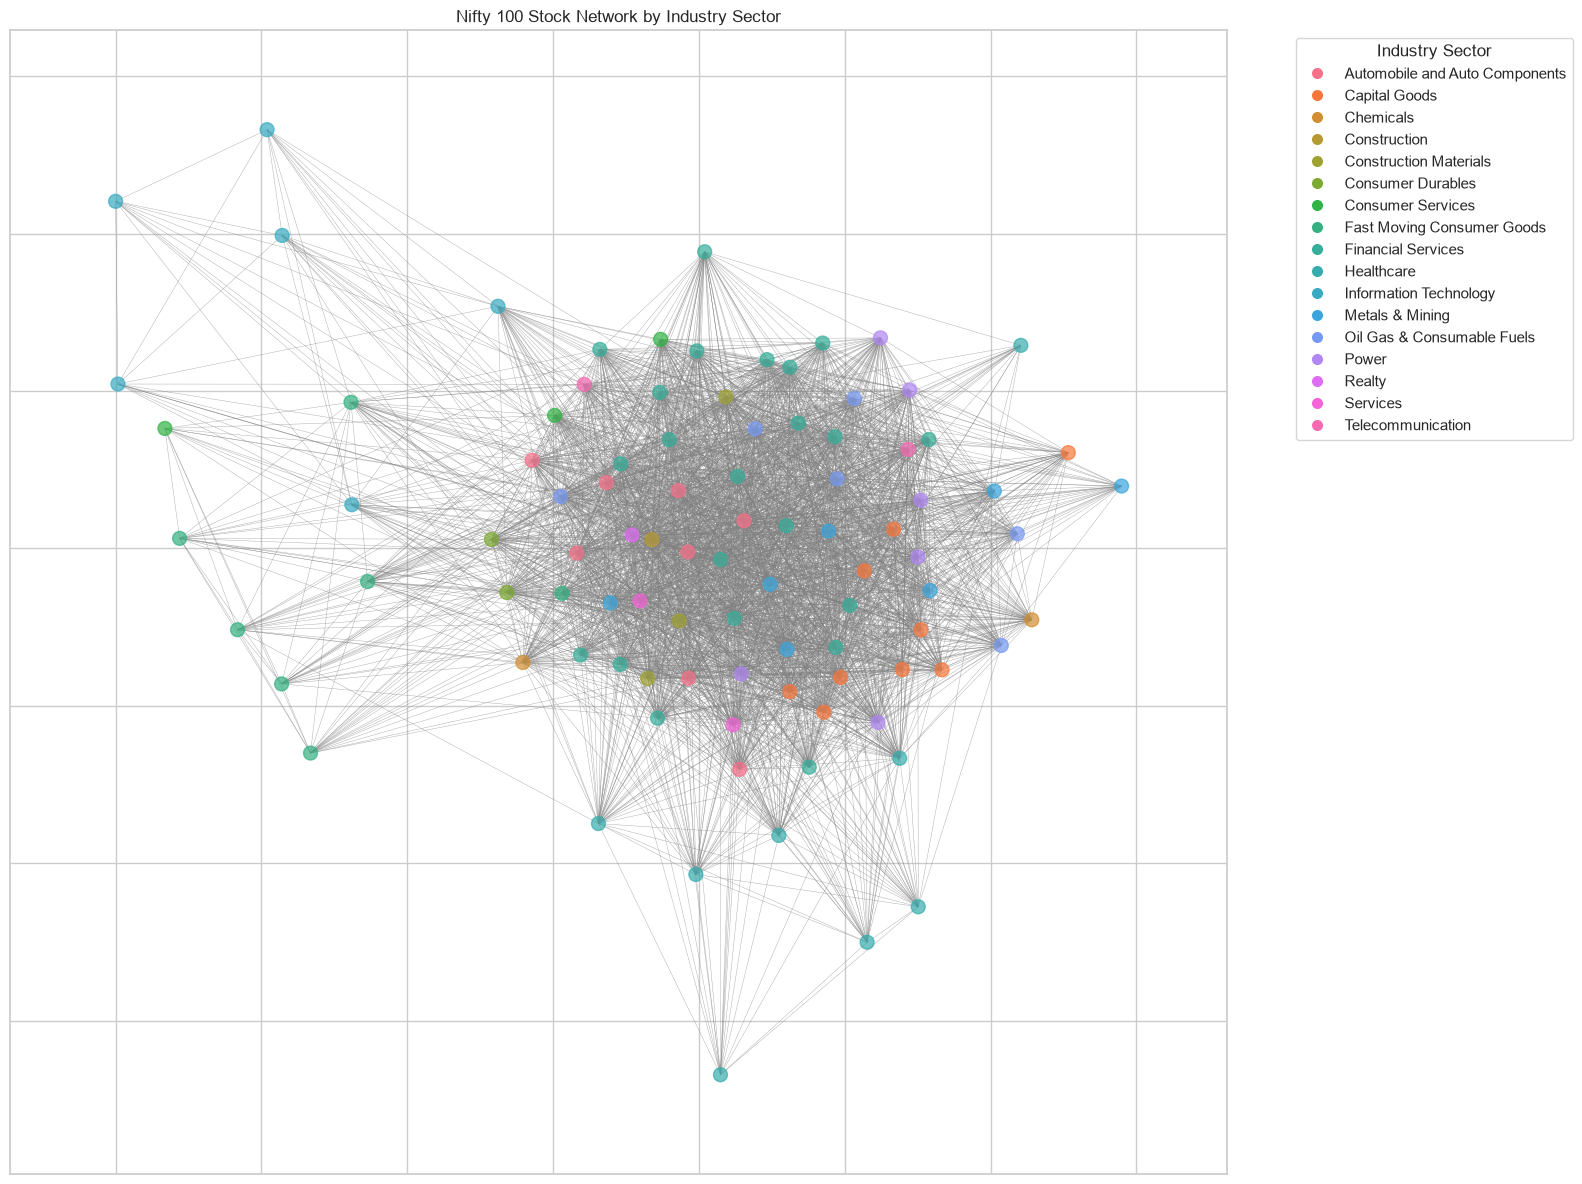

In [30]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42)

sectors = nx.get_node_attributes(G, 'sector')
unique_sectors = sorted(set(sectors.values()))

palette = sns.color_palette('husl', len(unique_sectors))
sector_colors = dict(zip(unique_sectors, palette))

node_colors = [sector_colors[sectors[node]] for node in G.nodes()]

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    node_size=100,
    with_labels=False,
    edge_color='gray',
    alpha=0.7,
    width=0.3
)
# Create legend handles
handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=color, markersize=9, label=sector)
    for sector, color in sector_colors.items()
]

plt.legend(handles=handles, title="Industry Sector",
           bbox_to_anchor=(1.05, 1), loc='upper left')

plt.title('Nifty 100 Stock Network by Industry Sector')
plt.tight_layout()

plt.show()


# plt.axis('off')
# plt.show()

In [31]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5,0.6,0.7,0.8,0.9]

results = []

for threshold in thresholds:
    adjacency = (correlation_matrix.abs() >= threshold).astype(int)
    adjacency = adjacency * (1 - np.eye(len(adjacency), dtype=int))

    G_temp = nx.from_pandas_adjacency(adjacency)

    results.append({
        'Threshold': threshold,
        'Nodes': G_temp.number_of_nodes(),
        'Edges': G_temp.number_of_edges(),
        'Density': nx.density(G_temp),
        'Avg Degree': np.mean([d for n, d in G_temp.degree()]),
        'Avg Clustering': nx.average_clustering(G_temp),
        'Components': nx.number_connected_components(G_temp)
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(3))

,Threshold,Nodes,Edges,Density,Avg Degree,Avg Clustering,Components
0,0.1,95,4210,0.943,88.632,0.956,1
1,0.2,95,2939,0.658,61.874,0.849,1
2,0.3,95,1545,0.346,32.526,0.783,2
3,0.4,95,647,0.145,13.621,0.627,20
4,0.5,95,199,0.045,4.189,0.439,40
5,0.6,95,55,0.012,1.158,0.194,62
6,0.7,95,19,0.004,0.400,0.053,79
7,0.8,95,4,0.001,0.084,0.000,91
8,0.9,95,0,0.000,0.000,0.000,95


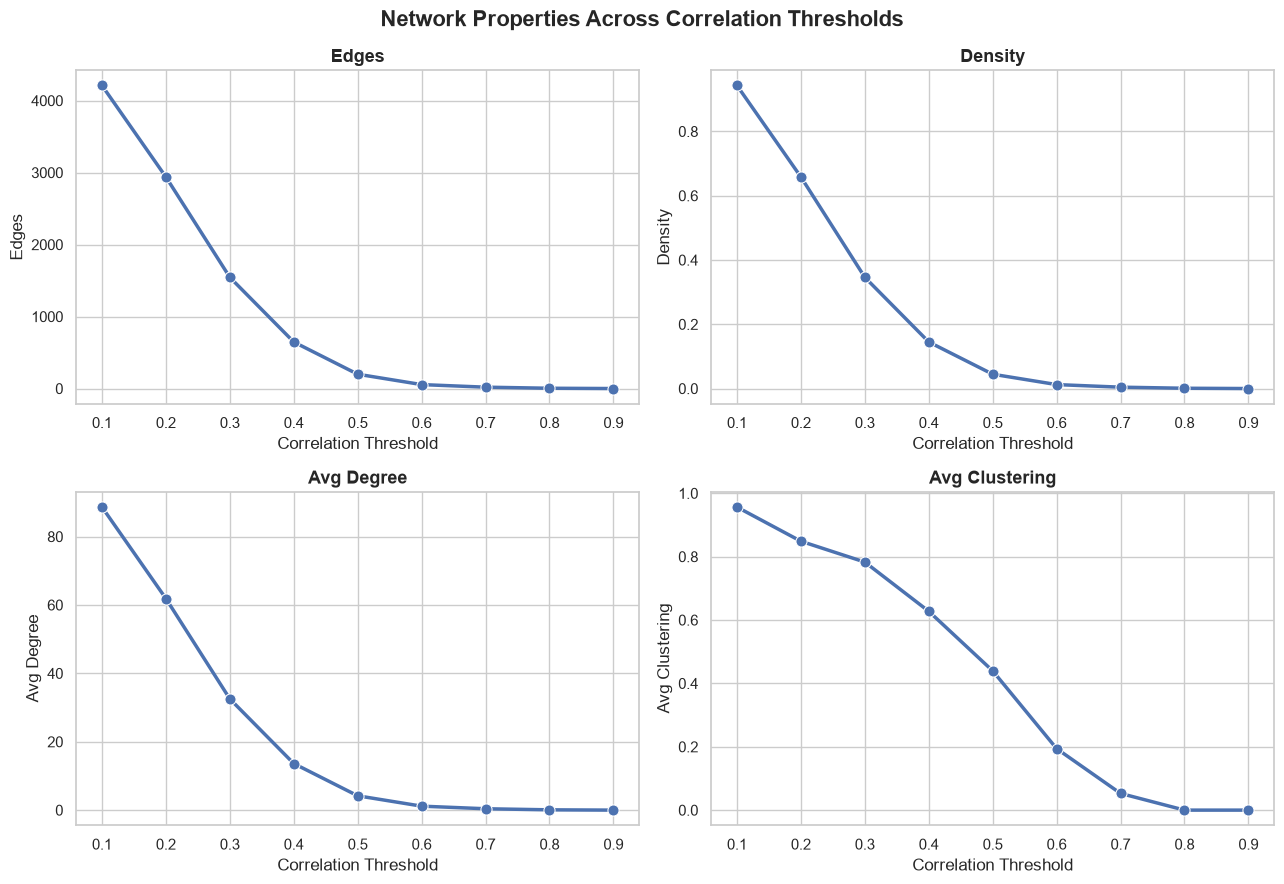

In [32]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = ['Edges', 'Density', 'Avg Degree', 'Avg Clustering']

for ax, metric in zip(axes.flat, metrics):
    sns.lineplot(
        data=threshold_df,
        x='Threshold',
        y=metric,
        marker='o',
        linewidth=2.5,
        markersize=8,
        ax=ax
    )
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_xlabel('Correlation Threshold')
    ax.set_ylabel(metric)

fig.suptitle(
    'Network Properties Across Correlation Thresholds',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

- based on the above, we choose threshold of around 0.34 for nifty 100
- based on above we choose threshold of around 0.2 for nifty 100

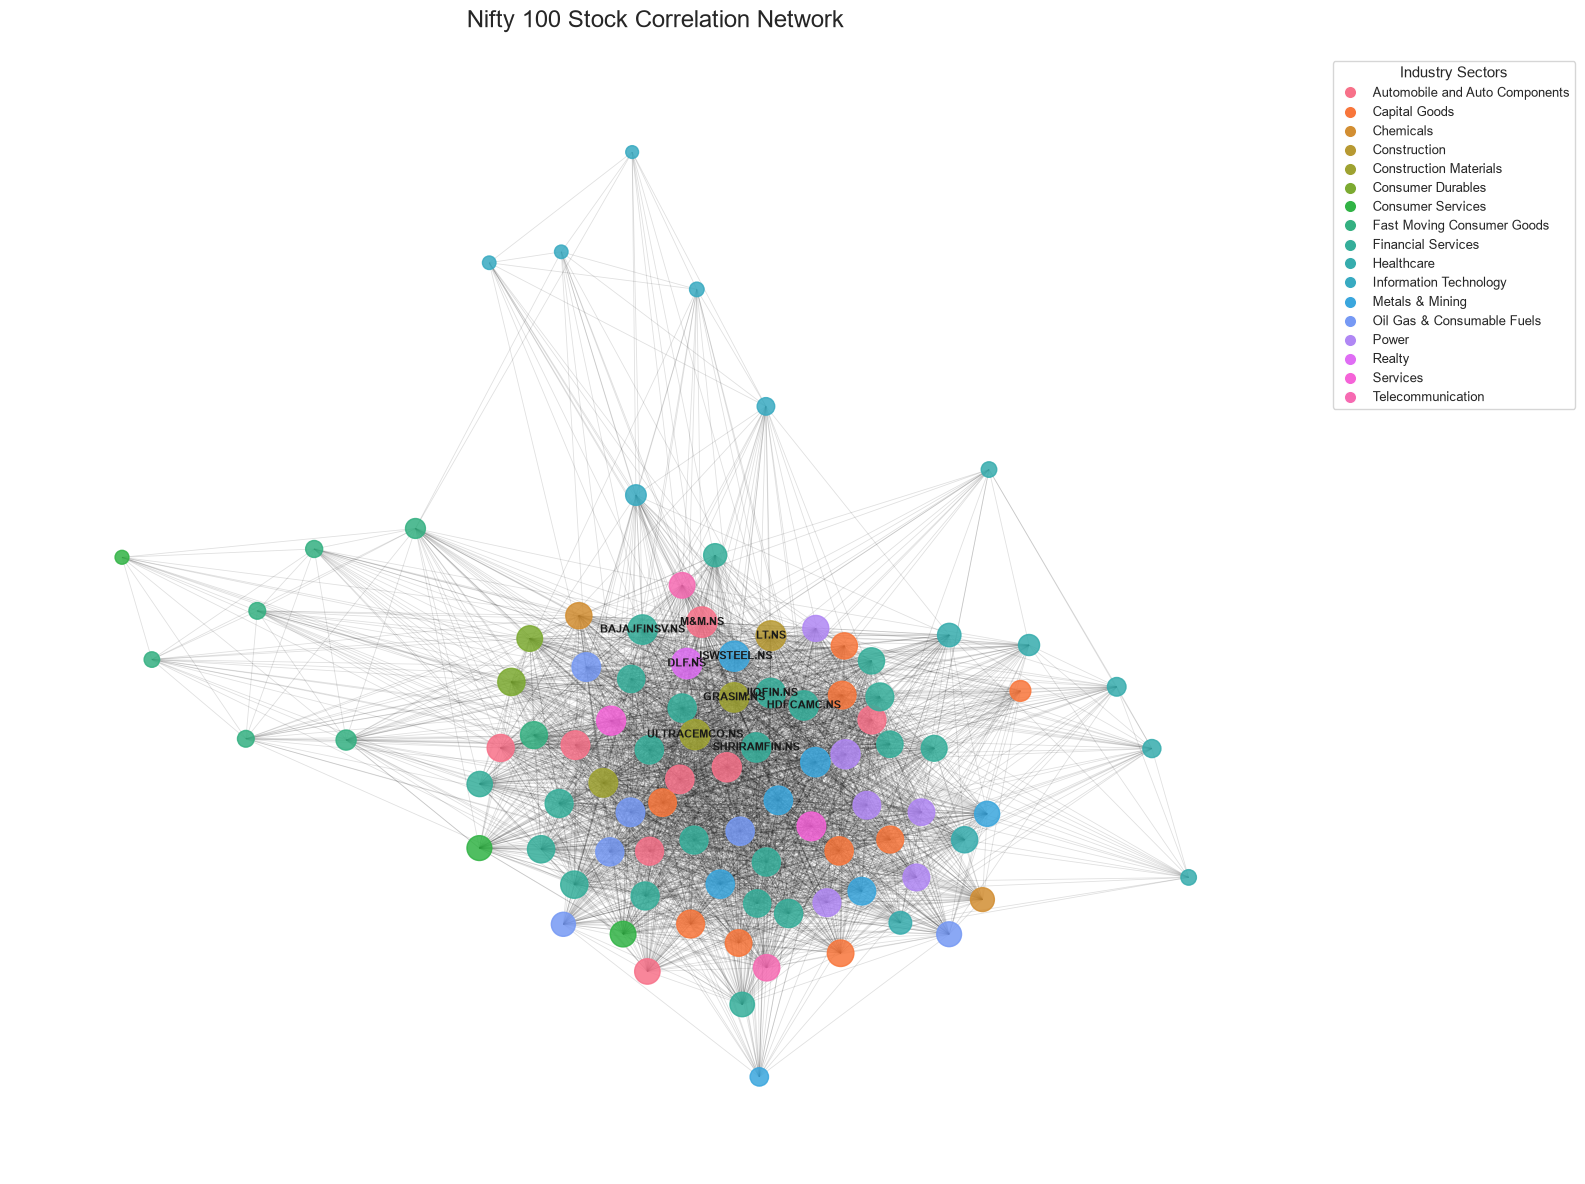

In [34]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42, k=0.25)

degrees = dict(G.degree())
node_sizes = [30 + degrees[n] * 5 for n in G.nodes()]

nx.draw_networkx_edges(
    G, pos,
    alpha=0.12,
    width=0.6,
    edge_color='black'
)

nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=[sector_colors.get(
        G.nodes[n].get('sector'), '#999999'
    ) for n in G.nodes()],
    alpha=0.85
)

# Label only the 10 most connected stocks
top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:10]

nx.draw_networkx_labels(
    G, pos,
    labels={n: n for n in top_nodes},
    font_size=8,
    font_weight='bold'
)

plt.title('Nifty 100 Stock Correlation Network', fontsize=17, pad=20)
plt.axis('off')
# Create industry legend
handles = [
    plt.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
        markersize=9,
        label=sector
    )
    for sector, color in sector_colors.items()
]

plt.legend(
    handles=handles,
    title='Industry Sectors',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=9,
    title_fontsize=11,
    frameon=True
)

plt.tight_layout()
plt.show()
# plt.tight_layout()
# plt.show()